# Lab 2: Transportation problem  

By Alex Ivanov  

## Objective  
The objective of this lab is to solve a transportation problem using linear programming techniques, including generating input data, analyzing sensitivity, stability, and visualizing results. Should be solved using both Python and Excel.

In [11]:
%pip install numpy pandas scipy matplotlib seaborn jupyterlab geopy requests networkx --quiet

Note: you may need to restart the kernel to use updated packages.


### Generate the data

In [ ]:
from functools import lru_cache
import numpy as np
import pandas as pd
import requests
from geopy.geocoders import Nominatim


geolocator = Nominatim(user_agent="route_api")
km = 1000
cost_per_km = 1.0
penalty = 1e9

# format with .2f if < penalty, format scientific if > penalty (1.01e+9)
float_format = lambda x: '{:,.2f}'.format(x) if x < penalty else '{:,.2e}'.format(x)


@lru_cache(maxsize=None)
def get_cost(city1, city2, cost_per_km=cost_per_km, rounding=2):
    """Get distance cost between two cities using OSM API"""

    if city1 == city2:
        return 0.0
    
    if "Fictional Supply" in (city1, city2):
        return penalty
    
    loc1 = geolocator.geocode(city1 + ", Ukraine")
    loc2 = geolocator.geocode(city2 + ", Ukraine")
    url = f"http://router.project-osrm.org/route/v1/driving/{loc1.longitude},{loc1.latitude};{loc2.longitude},{loc2.latitude}?overview=false"
    r = requests.get(url).json()
    return np.round(r["routes"][0]["distance"] / km, rounding)


# supply < demand -> fictitional supply
supply_names = ["Horodok", "Ostrog", "Rivne", "Fictional Supply"]
demand_names = ["Odesa", "Lviv", "Enerhodar", "Kyiv", "Sumy"]

n_supply = len(supply_names)
n_demand = len(demand_names)

# Use Geo API to get real distances
location_data = np.array(
    [[get_cost(s, d) for d in demand_names] for s in supply_names], dtype=float
)
cost_vec = location_data.flatten()

# Generate random supply/demand
rng = np.random.default_rng(42)
supply = rng.integers(1, 50, size=n_supply)
demand = rng.integers(1, 50, size=n_demand)

# Adjust fictional supply to match total demand
supply[-1] = max(0, np.sum(demand) - np.sum(supply[:-1]))

supply_sum = np.sum(supply[:-1])

df = pd.DataFrame(
    np.hstack((
        np.vstack((location_data, demand)),
        np.concatenate((supply, [0]))[:, np.newaxis]
    )), 
    index=np.concatenate((supply_names, ["Demand"])),
    columns=np.concatenate((demand_names, ["Supply"]))
)

print(df.to_string(float_format=float_format))

Supply:	 76 	 [ 5 38 33]
Demand:	 115 	 [22 43  5 35 10]
                    Odesa     Lviv  Enerhodar     Kyiv     Sumy  Supply
Horodok            819.78    29.03   1,329.69   567.91   902.17    5.00
Ostrog             666.56   228.63   1,094.23   332.45   666.72   38.00
Rivne              786.35   300.67   1,088.71   325.07   658.69   33.00
Fictional Supply 1.00e+09 1.00e+09   1.00e+09 1.00e+09 1.00e+09   39.00
Demand              22.00    43.00       5.00    35.00    10.00    0.00


### Solve transportation problem using Python

In [13]:
from scipy.optimize import linprog
import numpy as np


def solve_transportation_problem(cost_vec, supply, demand, bounds=None):
    n_supply, n_demand = len(supply), len(demand)
    res = linprog(
        c=cost_vec,
        A_ub=None,
        b_ub=None,
        A_eq=np.vstack(
            [
                np.kron(np.eye(n_supply), np.ones(n_demand)),
                np.kron(np.ones(n_supply), np.eye(n_demand)),
            ]
        ),
        b_eq=np.concatenate([supply, demand]),
        bounds=(0, None) if bounds is None else bounds,
        method="highs",
    )
    assert res.success, f"Optimization failed: {res.message}\n{res}"

    # Exclude fictitional supply row
    x = res.x.reshape(n_supply, n_demand)
    real_x = x[:-1, :]

    return x, real_x, res


x, real_x, res = solve_transportation_problem(cost_vec, supply, demand)
result_df = pd.DataFrame(
    np.hstack((np.vstack((x, demand)), np.concatenate((supply, [0]))[:, np.newaxis])),
    index=np.concatenate((supply_names, ["Demand"])),
    columns=np.concatenate((demand_names, ["Supply"])),
)
print(result_df.to_string(float_format=float_format), end="\n\n")

x_sum = real_x.sum()
print(f"Solution ({x_sum}) == supply ({supply_sum}): {np.isclose(x_sum, supply_sum)}")

optimal_cost = (real_x * location_data[:-1, :]).sum().round(2)
print("Calculated optimal cost:", optimal_cost)

                  Odesa  Lviv  Enerhodar  Kyiv  Sumy  Supply
Horodok            0.00  5.00       0.00  0.00  0.00    5.00
Ostrog             0.00 38.00       0.00  0.00  0.00   38.00
Rivne              0.00  0.00       0.00 33.00  0.00   33.00
Fictional Supply  22.00  0.00       5.00  2.00 10.00   39.00
Demand            22.00 43.00       5.00 35.00 10.00    0.00

Solution (76.0) == supply (76): True
Calculated optimal cost: 19560.4


### Visualize the data

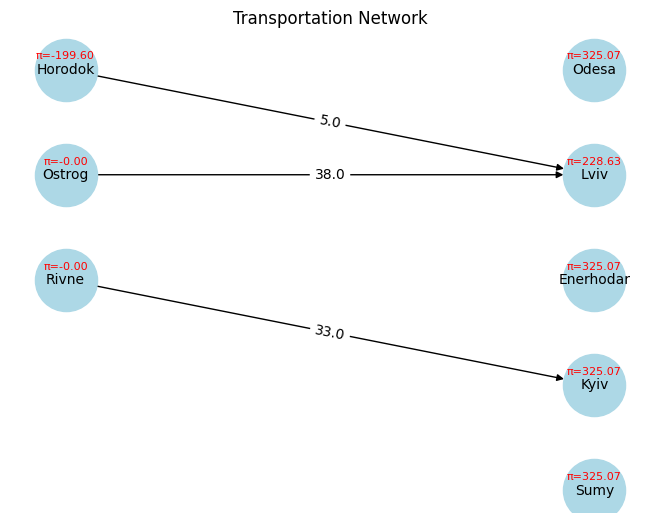

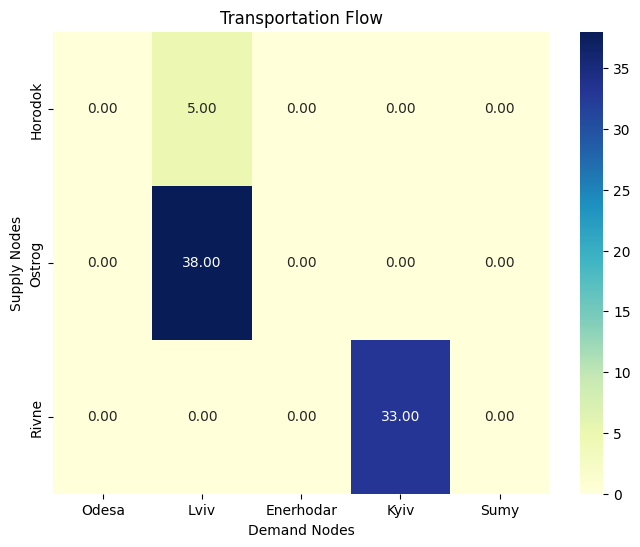

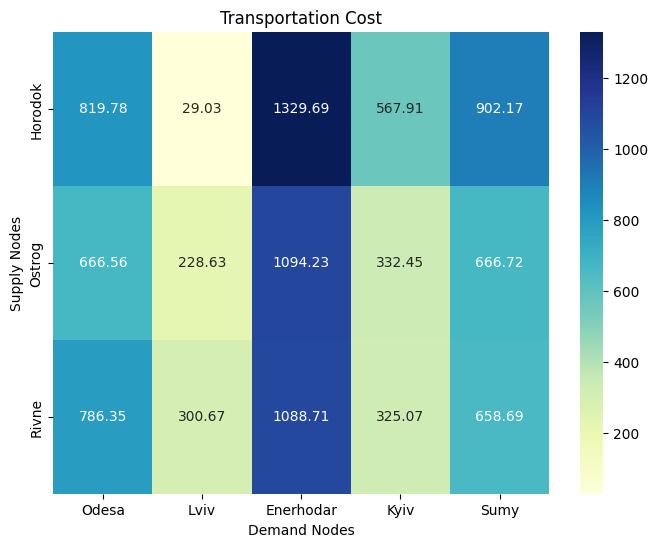

In [14]:
from typing import Literal, Sequence
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx


# Мережа: граф «постачальники → споживачі»
    # (Python: networkx.DiGraph, networkx.draw_networkx) з
    # підписами на ребрах (обсяги) та у вузлах (для тіньових цін).

def plot_network(real_x, supply_names, demand_names, shadow_prices=None):
    G = nx.DiGraph()

    # Add supply nodes
    for i, supply in enumerate(supply_names[:-1]):
        G.add_node(supply, pos=(0, -i))

    # Add demand nodes
    for j, demand in enumerate(demand_names):
        G.add_node(demand, pos=(2, -j))

    # Add edges with flow values
    for i, supply in enumerate(supply_names[:-1]):
        for j, demand in enumerate(demand_names):
            if real_x[i, j] > 0:
                G.add_edge(supply, demand, weight=real_x[i, j])

    pos = nx.get_node_attributes(G, 'pos')
    edge_labels = nx.get_edge_attributes(G, 'weight')
    nx.draw(G, pos, with_labels=True, node_size=2000, node_color='lightblue', font_size=10)
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels)
    
    if shadow_prices is not None:
        for i, supply in enumerate(supply_names[:-1]):
            plt.text(0, -i + 0.1, f"π={shadow_prices[i]:.2f}", fontsize=8, ha='center', color='red')
        for j, demand in enumerate(demand_names):
            plt.text(2, -j + 0.1, f"π={shadow_prices[n_supply + j]:.2f}", fontsize=8, ha='center', color='red')

    plt.title("Transportation Network")
    plt.axis('off')
    plt.show()


def heatmap_plot(
    matrix: np.ndarray,
    title="Heatmap",
    xlabel="Demand Nodes",
    ylabel="Supply Nodes",
    xticklabels: bool | int | Sequence[str] | Literal['auto'] = "auto",
    yticklabels: bool | int | Sequence[str] | Literal['auto'] = "auto",
):
    plt.figure(figsize=(8, 6))
    sns.heatmap(
        matrix,
        annot=True,
        fmt=".2f",
        cmap="YlGnBu",
        xticklabels=xticklabels,
        yticklabels=yticklabels,
    )
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.show()


plot_network(real_x, supply_names, demand_names, res.eqlin.marginals)
heatmap_plot(
    real_x,
    title="Transportation Flow",
    xticklabels=demand_names,
    yticklabels=supply_names[:-1],
)
heatmap_plot(
    location_data[:-1, :],
    title="Transportation Cost",
    xticklabels=demand_names,
    yticklabels=supply_names[:-1],
)

### Sensitivity analysis

In [24]:
import pandas as pd


print("Sensitivity analysis:", end="\n\n")

eqlin = np.array(list(map(float_format, res.eqlin.marginals)))
cheapest_additional_supply = np.argmin(res.eqlin.marginals)
cheapest_additional_demand = np.argmin(res.eqlin.marginals[n_supply:])
print(
    f"""Eqlin marginals:
Supply: {eqlin[:n_supply - 1]}
Cheapest additional source of supply: {supply_names[cheapest_additional_supply]} ({eqlin[cheapest_additional_supply]})
Demand: {eqlin[n_supply:]}
Cheapest additional source of demand: {demand_names[cheapest_additional_demand]} ({eqlin[n_supply + cheapest_additional_demand]})
"""
)


lower_marginals = np.array(list(map(float_format, res.lower.marginals))).reshape(
    n_supply, n_demand
)
print(
    f"""If a supply or demand b decreases by 1 for x >= b, 
the optimal cost decreases by the corresponding marginal value.
Lower marginals (x >= b):
{pd.DataFrame(lower_marginals, index=supply_names, columns=demand_names)}
"""
)

print(f"""Upper marginals (x <= b):
{np.array(list(map(float_format, res.upper.marginals))).reshape(n_supply, n_demand)
 }""")
print(
    f"""If a supply or demand b increases by 1 for x <= b, 
the optimal cost increases by the corresponding marginal value.
Upper marginals (x <= b):
{pd.DataFrame(np.array(list(map(float_format, res.upper.marginals))).reshape(n_supply, n_demand), index=supply_names, columns=demand_names)}
"""
)

Sensitivity analysis:

Eqlin marginals:
Supply: ['-199.60' '-0.00' '-0.00']
Cheapest additional source of supply: Horodok (-199.60)
Demand: ['325.07' '228.63' '325.07' '325.07' '325.07']
Cheapest additional source of demand: Lviv (228.63)

If a supply or demand b decreases by 1 for x >= b, 
the optimal cost decreases by the corresponding marginal value.
Lower marginals (x >= b):
                   Odesa   Lviv Enerhodar    Kyiv    Sumy
Horodok           694.31   0.00  1,204.22  442.44  776.70
Ostrog            341.49   0.00    769.16    7.38  341.65
Rivne             461.28  72.04    763.64    0.00  333.62
Fictional Supply    0.00  96.44      0.00    0.00    0.00

Upper marginals (x <= b):
[['0.00' '0.00' '0.00' '0.00' '0.00']
 ['0.00' '0.00' '0.00' '0.00' '0.00']
 ['0.00' '0.00' '0.00' '0.00' '0.00']
 ['0.00' '0.00' '0.00' '0.00' '0.00']]
If a supply or demand b increases by 1 for x <= b, 
the optimal cost increases by the corresponding marginal value.
Upper marginals (x <= b):
      

## Stability analysis

### Varying routes costs

In [16]:
import pandas as pd
import numpy as np


n_steps = 100
cost_variation = 0.5

rng = np.random.default_rng(42)
route_indices = rng.choice(n_supply * n_demand, size=3, replace=False)
route_indices_unravel = np.array([(i // n_demand, i % n_demand) for i in route_indices])
routes_str = ", ".join(
    [
        f"{supply_names[sup]} - {demand_names[dem]} ({sup}, {dem})"
        for sup, dem in route_indices_unravel
    ]
)
print(f"Varying costs on routes: {routes_str}", end="\n\n")

result_heat_map = []
for variations in np.linspace(1 - cost_variation, 1 + cost_variation, n_steps):
    varied_cost_vec = cost_vec.copy()

    # Vary costs on selected routes
    for i, route_index in enumerate(route_indices):
        varied_cost_vec[route_index] *= variations

    # Resolve transportation problem with varied costs
    _, real_x, _ = solve_transportation_problem(varied_cost_vec, supply, demand)

    results_count = np.unique(result_heat_map, axis=0).shape[0]
    # Append heat map row (1 if route used, 0 if not)
    result_heat_map.append((~np.isclose(real_x, 0)).astype(int))

    # Check if the plan is unique
    if np.unique(result_heat_map, axis=0).shape[0] > results_count:
        title = f"New unique plan found with cost variations {variations:.2f}:"
        print("-" * len(title))
        print(title)
        df = pd.DataFrame(real_x, index=supply_names[:-1], columns=demand_names)
        print(df.to_string(float_format=float_format))

        print("\nHeat map:")
        heat_map_df = pd.DataFrame(
            result_heat_map[-1], columns=demand_names, index=supply_names[:-1]
        )
        print(heat_map_df)
        print("-" * len(title), end="\n\n")

Varying costs on routes: Rivne - Kyiv (2, 3), Horodok - Lviv (0, 1), Rivne - Sumy (2, 4)

------------------------------------------------
New unique plan found with cost variations 0.50:
         Odesa  Lviv  Enerhodar  Kyiv  Sumy
Horodok   0.00  5.00       0.00  0.00  0.00
Ostrog    0.00 38.00       0.00  0.00  0.00
Rivne     0.00  0.00       0.00 33.00  0.00

Heat map:
         Odesa  Lviv  Enerhodar  Kyiv  Sumy
Horodok      0     1          0     0     0
Ostrog       0     1          0     0     0
Rivne        0     0          0     1     0
------------------------------------------------

------------------------------------------------
New unique plan found with cost variations 1.25:
         Odesa  Lviv  Enerhodar  Kyiv  Sumy
Horodok   0.00  5.00       0.00  0.00  0.00
Ostrog    0.00  5.00       0.00 33.00  0.00
Rivne     0.00 33.00       0.00  0.00  0.00

Heat map:
         Odesa  Lviv  Enerhodar  Kyiv  Sumy
Horodok      0     1          0     0     0
Ostrog       0     1      

### Varying supply/demand on one node

In [17]:
print("Varying supply/demand on one node:")
print("-" * 50, end="\n\n")

supply_variation, demand_variation = 20, 20
rng = np.random.default_rng(42)
supply_or_demand = rng.choice(["supply", "demand"])
result_log = {}

if supply_or_demand == "supply":
    node_index = rng.integers(0, n_supply - 1)
    node_name = supply_names[node_index]

    print(f"Varying supply on node {node_name} ({node_index})")
    variation_range = np.arange(-supply_variation, supply_variation + 1)
    base_value = supply[node_index]
    varied_values = base_value + variation_range
    varied_values = varied_values[varied_values >= 0]  # No negative supply

    for new_value in varied_values:
        new_supply = supply.copy()
        new_supply[node_index] = new_value

        # Adjust fictitious supply to maintain balance
        new_supply[-1] = max(0, np.sum(demand) - np.sum(new_supply[:-1]))
        
        _, real_x, _ = solve_transportation_problem(cost_vec, new_supply, demand)
        result_log[new_value] = (~np.isclose(real_x, 0)).astype(int)
else:
    node_index = rng.integers(0, n_demand)
    node_name = demand_names[node_index]

    print(f"Varying demand on node {node_name} ({node_index})")
    variation_range = np.arange(-demand_variation, demand_variation + 1)
    base_value = demand[node_index]
    varied_values = base_value + variation_range
    varied_values = varied_values[varied_values >= 0]  # No negative demand
    
    for new_value in varied_values:
        new_demand = demand.copy()
        new_demand[node_index] = new_value
        new_supply = supply.copy()

        # Adjust fictitious supply to maintain balance
        new_supply[-1] = max(0, np.sum(new_demand) - np.sum(new_supply[:-1]))

        _, real_x, _ = solve_transportation_problem(cost_vec, new_supply, new_demand)
        result_log[new_value] = (~np.isclose(real_x, 0)).astype(int)

unique_plans = np.unique(list(result_log.values()), axis=0)
print(f"Found {unique_plans.shape[0]} unique plans for varied {supply_or_demand}.")

for i, plan in enumerate(unique_plans):
    print(f"\nPlan {i + 1}:")
    heat_map_df = pd.DataFrame(plan, columns=demand_names, index=supply_names[:-1])
    print(heat_map_df)

Varying supply/demand on one node:
--------------------------------------------------

Varying supply on node Rivne (2)
Found 3 unique plans for varied supply.

Plan 1:
         Odesa  Lviv  Enerhodar  Kyiv  Sumy
Horodok      0     1          0     0     0
Ostrog       0     1          0     0     0
Rivne        0     0          0     1     0

Plan 2:
         Odesa  Lviv  Enerhodar  Kyiv  Sumy
Horodok      0     1          0     0     0
Ostrog       0     1          0     0     0
Rivne        0     0          0     1     1

Plan 3:
         Odesa  Lviv  Enerhodar  Kyiv  Sumy
Horodok      0     1          0     0     0
Ostrog       1     1          0     0     0
Rivne        0     1          0     1     1


## What-if analysis

### Adjusting demand by +1

In [18]:
import pandas as pd


demand_increase = 1
node_index = 1

print("What-if analysis:")
print("-" * 50, end="\n\n")

print("Increase demand at one node and compare cost change with shadow price")
print(
    f"Original solution:\n{result_df.to_string(float_format=float_format)}", end="\n\n"
)

node_name = demand_names[node_index]
print(f"Increase demand on node {node_name} ({node_index}) by {demand_increase}")

# Increase demand
new_demand = demand.copy()
new_demand[node_index] += demand_increase

# Adjust fictitious supply to maintain balance
new_supply = supply.copy()
new_supply[-1] += demand_increase

# Solve transportation problem with increased demand
x, real_x, _ = solve_transportation_problem(cost_vec, new_supply, new_demand)
demand_df = pd.DataFrame(x, index=supply_names, columns=demand_names).to_string(
    float_format=float_format
)
print(f"Solution with increased demand:\n{demand_df}", end="\n\n")

new_cost = (real_x * location_data[:-1, :]).sum().round(2)
cost_change = (new_cost - optimal_cost).round(2)
shadow_price = res.eqlin.marginals[n_supply + node_index]
print(
    f"Cost change: {new_cost} - {optimal_cost} = {cost_change}\n"
    f"Shadow price for demand at node {node_name} ({node_index}): {shadow_price}\n"
    "It doesn't equal because the structure of the problem is changed by "
    "increasing supply, not only demand.\n" + ("-" * 50)
)

What-if analysis:
--------------------------------------------------

Increase demand at one node and compare cost change with shadow price
Original solution:
                  Odesa  Lviv  Enerhodar  Kyiv  Sumy  Supply
Horodok            0.00  5.00       0.00  0.00  0.00    5.00
Ostrog             0.00 38.00       0.00  0.00  0.00   38.00
Rivne              0.00  0.00       0.00 33.00  0.00   33.00
Fictional Supply  22.00  0.00       5.00  2.00 10.00   39.00
Demand            22.00 43.00       5.00 35.00 10.00    0.00

Increase demand on node Lviv (1) by 1
Solution with increased demand:
                  Odesa  Lviv  Enerhodar  Kyiv  Sumy
Horodok            0.00  5.00       0.00  0.00  0.00
Ostrog             0.00 38.00       0.00  0.00  0.00
Rivne              0.00  1.00       0.00 32.00  0.00
Fictional Supply  22.00  0.00       5.00  3.00 10.00

Cost change: 19536.0 - 19560.4 = -24.4
Shadow price for demand at node Lviv (1): 228.63
It doesn't equal because the structure of the prob

### Forbidding one of the routes

In [19]:
import numpy as np
import pandas as pd


print(
    "Forbid one of the routes and see the result\n\n"
    f"Original solution:\n{result_df.to_string(float_format=float_format)}",
    end="\n\n",
)

rng = np.random.default_rng(42)
forbid_idx = rng.choice(n_supply * n_demand)
sup, dem = forbid_idx // n_demand, forbid_idx % n_demand
forbid_name = f"{supply_names[sup]} - {demand_names[dem]} ({sup}, {dem})"
print(f"Forbidding route {forbid_name}", end="\n\n")

bounds = [
    (0, None) if idx != forbid_idx else (0, 0) for idx in np.arange(n_supply * n_demand)
]

# Solve transportation problem with increased demand
x, real_x, _ = solve_transportation_problem(cost_vec, supply, demand, bounds)
demand_df = pd.DataFrame(x, index=supply_names, columns=demand_names).to_string(
    float_format=float_format
)
print(f"Solution with increased demand:\n{demand_df}", end="\n\n")

new_cost = (real_x * location_data[:-1, :]).sum().round(2)
cost_change = (new_cost - optimal_cost).round(2)
print(f"Cost change: {new_cost} - {optimal_cost} = {cost_change}")

Forbid one of the routes and see the result

Original solution:
                  Odesa  Lviv  Enerhodar  Kyiv  Sumy  Supply
Horodok            0.00  5.00       0.00  0.00  0.00    5.00
Ostrog             0.00 38.00       0.00  0.00  0.00   38.00
Rivne              0.00  0.00       0.00 33.00  0.00   33.00
Fictional Supply  22.00  0.00       5.00  2.00 10.00   39.00
Demand            22.00 43.00       5.00 35.00 10.00    0.00

Forbidding route Horodok - Lviv (0, 1)

Solution with increased demand:
                  Odesa  Lviv  Enerhodar  Kyiv  Sumy
Horodok            0.00  0.00       0.00  5.00  0.00
Ostrog             0.00 38.00       0.00  0.00  0.00
Rivne              0.00  5.00       0.00 28.00  0.00
Fictional Supply  22.00  0.00       5.00  2.00 10.00

Cost change: 22132.8 - 19560.4 = 2572.4


### Adjust transportation cost on the route with the highest flow

In [20]:
import numpy as np
import pandas as pd


print("Adjust transportation cost on the route with the highest flow")
print("-" * 50, end="\n\n")

real_x_flow = real_x.copy()
sup, dem = np.unravel_index(np.argmax(real_x_flow, axis=None), real_x_flow.shape)
max_flow_route = f"{supply_names[sup]} - {demand_names[dem]} ({sup}, {dem})"
print(f"Route with the highest flow: {max_flow_route}", end="\n\n")

# Increase transportation cost on the route with the highest flow
cost_vec[sup * n_demand + dem] *= 1.5
print(f"New cost for route {max_flow_route}: {cost_vec[sup * n_demand + dem]}", end="\n\n")

# Solve transportation problem with increased cost
x, real_x, _ = solve_transportation_problem(cost_vec, supply, demand)
demand_df = pd.DataFrame(x, index=supply_names, columns=demand_names).to_string(
    float_format=float_format
)
print(f"Solution with increased cost:\n{demand_df}", end="\n\n")

new_cost = (real_x * location_data[:-1, :]).sum().round(2)
cost_change = (new_cost - optimal_cost).round(2)
print(f"Cost change: {new_cost} - {optimal_cost} = {cost_change}")

Adjust transportation cost on the route with the highest flow
--------------------------------------------------

Route with the highest flow: Ostrog - Lviv (1, 1)

New cost for route Ostrog - Lviv (1, 1): 342.945

Solution with increased cost:
                  Odesa  Lviv  Enerhodar  Kyiv  Sumy
Horodok            0.00  5.00       0.00  0.00  0.00
Ostrog             0.00  3.00       0.00 35.00  0.00
Rivne              0.00 33.00       0.00  0.00  0.00
Fictional Supply  22.00  2.00       5.00  0.00 10.00

Cost change: 22388.9 - 19560.4 = 2828.5
